# 03 - Anomaly detection

Isolation Forest and an autoencoder, trained on normal traffic only, so they never see an attack before test time.
Same splits, same threshold rule (1% FPR on validation) and same `results.json` as `02_supervised`, so the numbers are directly comparable.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline

from netad.data import load_unsw_frame, overlap_with_train, distinct_rows, train_val_split, CATEGORICAL, FEATURES
from netad.preprocessing import build_preprocessor
from netad.models.autoencoder import train_autoencoder, reconstruction_error, save_autoencoder
from netad.evaluation import (
    FIGURES_DIR, evaluate_binary, choose_threshold, evaluate_test, save_result, results_table,
)

In [3]:
train_df = load_unsw_frame("train")
test_df = load_unsw_frame("test")

X_test = test_df[FEATURES]
y_test = test_df["label"]
y_test_multi = test_df["attack_cat"]
unseen = ~overlap_with_train(train_df, test_df)
distinct = distinct_rows(test_df)

X_tr, X_val, y_tr, y_val = train_val_split(train_df, "label")
val_categories = train_df.loc[X_val.index, "attack_cat"]
X_normal = X_tr[y_tr == 0]

MAX_FPR = 0.01
torch.manual_seed(42)

len(X_normal), len(X_tr), len(X_val), len(X_test)

(41367, 80752, 20189, 82332)

Training uses only the normal rows of the training part. The preprocessor is fitted on them too, so protocols and services that only attacks use end up in the "infrequent" one-hot column.

Validation keeps both classes. With an FPR budget the threshold is set by how normal validation flows score (about their 99th percentile), attack labels don't move it.

## Isolation Forest

Random trees that split on random features at random values. A flow that gets isolated after few splits is unusual. Anomaly score: `-score_samples` (higher = more anomalous). `contamination` is not used, the threshold comes from validation like for the other models.

A few settings are compared on validation partial ROC-AUC (FPR <= 1%): how many normal flows each tree is built on (`max_samples`, 1.0 = all of them) and whether the one-hot columns are used, since random splits on 0/1 columns isolate little. This uses the attack labels of validation, so the choice is not completely label free; the grid is kept small for that reason.

In [4]:
def anomaly_scores(model, X):
    return -model.score_samples(X)


columns = {"all": None, "numeric only": CATEGORICAL}

iforest = {}
for max_samples in [256, 1024, 4096, 16384, 1.0]:
    for cols, exclude in columns.items():
        model = make_pipeline(
            build_preprocessor(exclude=exclude),
            IsolationForest(n_estimators=300, max_samples=max_samples, random_state=42, n_jobs=-1),
        ).fit(X_normal)
        s_val = anomaly_scores(model, X_val)
        iforest[(len(X_normal) if max_samples == 1.0 else max_samples, cols)] = {
            "model": model,
            "params": {"n_estimators": 300, "max_samples": max_samples, "excluded": exclude or []},
            "val_pauc": roc_auc_score(y_val, s_val, max_fpr=MAX_FPR),
            "val_roc_auc": roc_auc_score(y_val, s_val),
        }

pd.DataFrame(
    {k: {"val pAUC": v["val_pauc"], "val ROC-AUC": v["val_roc_auc"]} for k, v in iforest.items()}
).T.rename_axis(["max_samples", "columns"]).round(4)

val pAUC  val ROC-AUC
max_samples columns                            
256         all             0.4987       0.7665
            numeric only    0.4984       0.8311
1024        all             0.5090       0.7747
            numeric only    0.5026       0.8128
4096        all             0.5187       0.7810
            numeric only    0.5130       0.8068
16384       all             0.5371       0.7926
            numeric only    0.5265       0.8088
41367       all             0.5459       0.7950
            numeric only    0.5352       0.8067

In [5]:
best = max(iforest.values(), key=lambda v: v["val_pauc"])
model = best["model"]
best["params"]

{'n_estimators': 300, 'max_samples': 1.0, 'excluded': []}

In [6]:
s_val = anomaly_scores(model, X_val)
s_test = anomaly_scores(model, X_test)
threshold = choose_threshold(y_val, s_val, "fpr", max_fpr=MAX_FPR)

metrics = {
    "val": evaluate_binary(y_val, s_val, threshold, categories=val_categories),
    **evaluate_test(evaluate_binary, y_test, s_test, unseen, distinct, categories=y_test_multi, threshold=threshold),
}
save_result("IsolationForest", "binary", metrics, {"threshold_mode": "fpr", "max_fpr": MAX_FPR, **best["params"]})

pd.DataFrame({k: {m: v[m] for m in ["recall", "macro_detection", "fpr", "precision", "roc_auc", "pr_auc"]} for k, v in metrics.items()}).T.round(4)

,recall,macro_detection,fpr,precision,roc_auc,pr_auc
val,0.1688,0.2490,0.0100,0.9416,0.7950,0.7993
test,0.6119,0.4764,0.0264,0.9660,0.8811,0.9121
test_unseen,0.5751,0.4333,0.0254,0.9606,0.8708,0.8957
test_distinct,0.2948,0.3786,0.0180,0.9122,0.7961,0.7476


Recall on validation and on test are far apart. Per category, with the share of each category among the attacks:

In [7]:
def per_category(m):
    cats = {c: v for c, v in m["by_category"].items() if c != "Normal"}
    total = sum(v["n"] for v in cats.values())
    return pd.DataFrame({c: {"share of attacks": v["n"] / total, "flagged": v["flagged"]} for c, v in cats.items()}).T


pd.concat({s: per_category(metrics[s]) for s in ["val", "test", "test_distinct"]}, axis=1).round(3)

val                     test          \
               share of attacks flagged share of attacks flagged   
Analysis                  0.011   0.241            0.015   0.885   
Backdoor                  0.010   0.456            0.013   0.909   
DoS                       0.061   0.285            0.090   0.699   
Exploits                  0.380   0.157            0.246   0.358   
Fuzzers                   0.303   0.033            0.134   0.225   
Generic                   0.080   0.864            0.416   0.957   
Reconnaissance            0.130   0.040            0.077   0.096   
Shellcode                 0.022   0.000            0.008   0.000   
Worms                     0.002   0.167            0.001   0.159   

                  test_distinct          
               share of attacks flagged  
Analysis                  0.021   0.825  
Backdoor                  0.016   0.847  
DoS                       0.079   0.391  
Exploits                  0.350   0.174  
Fuzzers                   0.223   0.115  
Generic                   0.168   0.800  
Reconnaissance            0.124   0.096  
Shellcode                 0.017   0.000  
Worms                     0.002   0.159

Scores of normal flows, validation vs test, against the threshold (same check as for the random forest in `02_supervised`):

In [8]:
normal_val = s_val[(y_val == 0).to_numpy()]
normal_test = s_test[(y_test == 0).to_numpy()]

pd.DataFrame({
    "validation": pd.Series(normal_val).quantile([0.5, 0.9, 0.95, 0.99]),
    "test": pd.Series(normal_test).quantile([0.5, 0.9, 0.95, 0.99]),
}).rename_axis("quantile").round(4).assign(threshold=round(threshold, 4))

,validation,test,threshold
quantile,,,
0.50,0.3822,0.3974,0.5574
0.90,0.4493,0.4757,0.5574
0.95,0.4764,0.5079,0.5574
0.99,0.5573,0.6004,0.5574


## Autoencoder

A network `d -> 32 -> 16 -> k -> 16 -> 32 -> d` (ReLU, linear bottleneck and output) trained to reconstruct normal flows, `src/netad/models/autoencoder.py`. A flow it reconstructs badly doesn't look like the normal traffic it learned. Score: mean squared error of each flow (one score per flow).

- Input: the same preprocessor as for Isolation Forest, fitted on the normal training flows. No other scaling. d = 56, not 59: the one-hot columns are built from normal flows only, where `proto` ospf and unas and `service` pop3 fall under the `min_frequency` cut (in the training part: 49, 0 and 4 normal flows, against 116, 364 and 879 attacks).
- Adam with lr 1e-3, shuffled batches of 256, MSE loss (mean). Early stopping (patience 10; the 500 epoch cap is never reached) on the reconstruction loss of the normal validation flows; validation attacks play no part in training.
- Bottleneck size k in {4, 8, 16} compared on validation partial ROC-AUC, same rule and same caveat as for Isolation Forest.
- Seed 42. Weights, preprocessor and threshold go to `models/` (not in git), the architecture to `results.json`.

In [9]:
pre = build_preprocessor().fit(X_normal)
Z_normal, Z_val, Z_test = (np.asarray(pre.transform(X), dtype=np.float32) for X in (X_normal, X_val, X_test))
Z_val_normal = Z_val[(y_val == 0).to_numpy()]

Z_normal.shape, Z_val_normal.shape

((41367, 56), (10342, 56))

In [10]:
autoencoders = {}
for k in [4, 8, 16]:
    ae_model, history = train_autoencoder(Z_normal, Z_val_normal, bottleneck=k)
    scores = reconstruction_error(ae_model, Z_val)
    autoencoders[k] = {
        "model": ae_model,
        "history": pd.DataFrame(history).set_index("epoch"),
        "val_pauc": roc_auc_score(y_val, scores, max_fpr=MAX_FPR),
        "val_roc_auc": roc_auc_score(y_val, scores),
    }

pd.DataFrame({
    k: {
        "epochs run": len(a["history"]),
        "best epoch": a["history"]["val_loss"].idxmin(),
        "val loss (normal)": a["history"]["val_loss"].min(),
        "val pAUC": a["val_pauc"],
        "val ROC-AUC": a["val_roc_auc"],
    }
    for k, a in autoencoders.items()
}).T.rename_axis("bottleneck").round(4)

,epochs run,best epoch,val loss (normal),val pAUC,val ROC-AUC
bottleneck,,,,,
4,217.0,207.0,0.0424,0.5616,0.7963
8,235.0,225.0,0.0142,0.5570,0.8511
16,170.0,160.0,0.0143,0.5359,0.7763


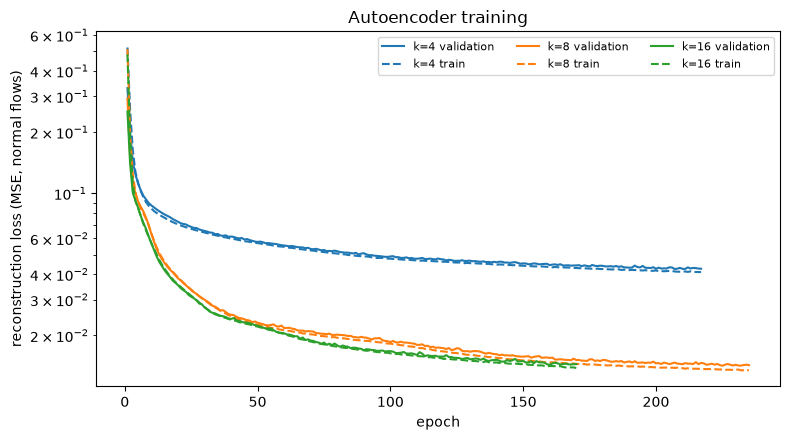

4

In [11]:
best_k = max(autoencoders, key=lambda k: autoencoders[k]["val_pauc"])
ae = autoencoders[best_k]

fig, ax = plt.subplots(figsize=(8, 4.5))
for k, a in autoencoders.items():
    line, = ax.plot(a["history"].index, a["history"]["val_loss"], label=f"k={k} validation")
    ax.plot(a["history"].index, a["history"]["train_loss"], linestyle="--", color=line.get_color(), label=f"k={k} train")
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("reconstruction loss (MSE, normal flows)")
ax.set_title("Autoencoder training")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "autoencoder_loss.png", dpi=120)
plt.show()
best_k

In [12]:
s_val_ae = reconstruction_error(ae["model"], Z_val)
s_test_ae = reconstruction_error(ae["model"], Z_test)
ae_threshold = choose_threshold(y_val, s_val_ae, "fpr", max_fpr=MAX_FPR)

ae_metrics = {
    "val": evaluate_binary(y_val, s_val_ae, ae_threshold, categories=val_categories),
    **evaluate_test(evaluate_binary, y_test, s_test_ae, unseen, distinct, categories=y_test_multi, threshold=ae_threshold),
}
ae_params = {
    "threshold_mode": "fpr", "max_fpr": MAX_FPR,
    "n_features": Z_normal.shape[1], "hidden": [32, 16], "bottleneck": best_k,
    "epochs": int(ae["history"]["val_loss"].idxmin()), "batch_size": 256, "lr": 1e-3, "patience": 10, "seed": 42,
}
save_result("Autoencoder", "binary", ae_metrics, ae_params)
save_autoencoder(ae["model"], pre, ae_threshold)

pd.DataFrame({k: {m: v[m] for m in ["recall", "macro_detection", "fpr", "precision", "roc_auc", "pr_auc"]} for k, v in ae_metrics.items()}).T.round(4)

,recall,macro_detection,fpr,precision,roc_auc,pr_auc
val,0.1820,0.2697,0.0100,0.9456,0.7963,0.8187
test,0.6023,0.4635,0.0319,0.9586,0.9091,0.9337
test_unseen,0.5798,0.4360,0.0310,0.9528,0.9053,0.9239
test_distinct,0.2969,0.3706,0.0217,0.8968,0.8464,0.7958


In [13]:
pd.DataFrame({
    "validation": pd.Series(s_val_ae[(y_val == 0).to_numpy()]).quantile([0.5, 0.9, 0.95, 0.99]),
    "test": pd.Series(s_test_ae[(y_test == 0).to_numpy()]).quantile([0.5, 0.9, 0.95, 0.99]),
}).rename_axis("quantile").round(4).assign(threshold=round(ae_threshold, 4))

,validation,test,threshold
quantile,,,
0.50,0.0266,0.0297,0.3105
0.90,0.0753,0.1108,0.3105
0.95,0.1069,0.2151,0.3105
0.99,0.3102,0.6251,0.3105


In [14]:
pd.concat({s: per_category(ae_metrics[s]) for s in ["val", "test", "test_distinct"]}, axis=1).round(3)

val                     test          \
               share of attacks flagged share of attacks flagged   
Analysis                  0.011   0.278            0.015   0.852   
Backdoor                  0.010   0.417            0.013   0.899   
DoS                       0.061   0.270            0.090   0.628   
Exploits                  0.380   0.161            0.246   0.339   
Fuzzers                   0.303   0.057            0.134   0.240   
Generic                   0.080   0.856            0.416   0.958   
Reconnaissance            0.130   0.079            0.077   0.094   
Shellcode                 0.022   0.018            0.008   0.003   
Worms                     0.002   0.292            0.001   0.159   

                  test_distinct          
               share of attacks flagged  
Analysis                  0.021   0.776  
Backdoor                  0.016   0.829  
DoS                       0.079   0.369  
Exploits                  0.350   0.186  
Fuzzers                   0.223   0.123  
Generic                   0.168   0.799  
Reconnaissance            0.124   0.091  
Shellcode                 0.017   0.003  
Worms                     0.002   0.159

## Comparison with the supervised models

All binary models in `results.json`, threshold at 1% FPR on validation for each.

- All rows: the traffic as it comes. A DoS really produces many identical flows and each one is an alert, so FPR and alert volume are read here.
- Distinct rows: each feature vector + category once. Counts how many different attack flows a model catches, without a few flows repeated thousands of times weighing in; models are compared here.
- Recall depends on which categories are frequent in the subset, `macro_detection` (mean rate over the 9 attack categories) does not.

In [15]:
cols = ["recall", "macro_detection", "fpr", "precision", "roc_auc"]
pd.concat({subset: results_table("binary", subset, cols) for subset in ["test", "test_unseen", "test_distinct"]}, axis=1).round(3)

test                                           \
                      recall macro_detection    fpr precision roc_auc   
Dummy (prior)          0.000           0.000  0.000     0.000   0.500   
LogisticRegression     0.804           0.749  0.025     0.975   0.968   
RandomForest           0.891           0.882  0.040     0.965   0.982   
HistGradientBoosting   0.920           0.918  0.048     0.959   0.985   
RandomForest (no TTL)  0.886           0.879  0.043     0.962   0.980   
IsolationForest        0.612           0.476  0.026     0.966   0.881   
Autoencoder            0.602           0.463  0.032     0.959   0.909   

                      test_unseen                                           \
                           recall macro_detection    fpr precision roc_auc   
Dummy (prior)               0.000           0.000  0.000     0.000   0.500   
LogisticRegression          0.772           0.710  0.023     0.973   0.963   
RandomForest                0.871           0.869  0.037     0.962   0.979   
HistGradientBoosting        0.906           0.910  0.047     0.954   0.983   
RandomForest (no TTL)       0.865           0.864  0.040     0.959   0.977   
IsolationForest             0.575           0.433  0.025     0.961   0.871   
Autoencoder                 0.580           0.436  0.031     0.953   0.905   

                      test_distinct                                           
                             recall macro_detection    fpr precision roc_auc  
Dummy (prior)                 0.000           0.000  0.000     0.000   0.500  
LogisticRegression            0.631           0.694  0.024     0.943   0.943  
RandomForest                  0.798           0.859  0.039     0.928   0.968  
HistGradientBoosting          0.855           0.904  0.048     0.919   0.973  
RandomForest (no TTL)         0.791           0.855  0.042     0.923   0.965  
IsolationForest               0.295           0.379  0.018     0.912   0.796  
Autoencoder                   0.297           0.371  0.022     0.897   0.846

Detection rate per attack category, the two anomaly detectors vs the best supervised model (random forest), on all test rows and on the distinct ones:

In [16]:
by_category = pd.DataFrame({
    (name, subset): {c: v["flagged"] for c, v in results_table("binary", subset, ["by_category"]).loc[name, "by_category"].items()}
    for name in ["RandomForest", "IsolationForest", "Autoencoder"]
    for subset in ["test", "test_distinct"]
})
by_category.round(3)

RandomForest               IsolationForest                \
                       test test_distinct            test test_distinct   
Analysis              0.914         0.870           0.885         0.825   
Backdoor              0.988         0.980           0.909         0.847   
DoS                   0.957         0.919           0.699         0.391   
Exploits              0.942         0.928           0.358         0.174   
Fuzzers               0.382         0.303           0.225         0.115   
Generic               0.992         0.976           0.957         0.800   
Normal                0.040         0.039           0.026         0.018   
Reconnaissance        0.962         0.954           0.096         0.096   
Shellcode             0.870         0.870           0.000         0.000   
Worms                 0.932         0.932           0.159         0.159   

               Autoencoder                
                      test test_distinct  
Analysis             0.852         0.776  
Backdoor             0.899         0.829  
DoS                  0.628         0.369  
Exploits             0.339         0.186  
Fuzzers              0.240         0.123  
Generic              0.958         0.799  
Normal               0.032         0.022  
Reconnaissance       0.094         0.091  
Shellcode            0.003         0.003  
Worms                0.159         0.159

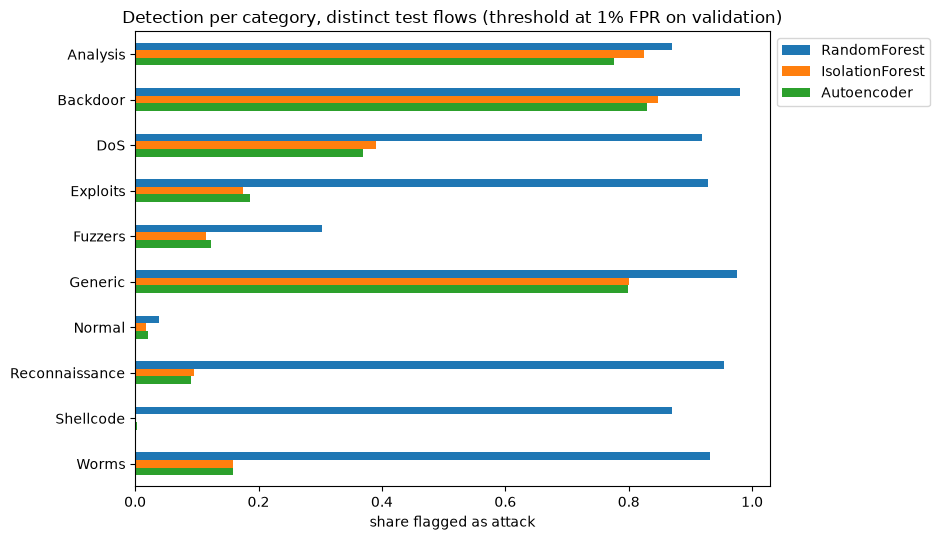

In [17]:
ax = by_category.xs("test_distinct", axis=1, level=1).plot.barh(figsize=(9.5, 5.5))
ax.invert_yaxis()
ax.set_xlabel("share flagged as attack")
ax.set_title("Detection per category, distinct test flows (threshold at 1% FPR on validation)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.figure.tight_layout()
ax.figure.savefig(FIGURES_DIR / "anomaly_detection_by_category.png", dpi=120)
plt.show()

## Conclusions

1. **Neither anomaly detector comes close to the supervised models.** On distinct test rows, where models are compared: Isolation Forest catches 29% of attacks (`macro_detection` 0.38), the autoencoder 30% (0.37), the random forest 80% (0.86). On all test rows: 61%, 60% and 89%, at 2.6%, 3.2% and 4.0% FPR. Expected: the random forest was shown what attacks look like, the other two only know normal traffic.
2. **The autoencoder ranks better overall, not where the threshold sits.** ROC-AUC on distinct test rows is 0.85 against 0.80 for Isolation Forest, yet at the 1% FPR threshold both catch the same share. Validation pAUC is 0.56 for the autoencoder and 0.55 for Isolation Forest: below 1% FPR both rank attacks barely better than chance.
3. **Both catch the same attacks.** On distinct test rows both flag about 80% of Backdoor, Analysis and Generic, under 40% of DoS, under 20% of Exploits, Fuzzers and Reconnaissance, and almost no Shellcode (0-0.3%). Attacks that look like ordinary flows go through.
4. **Each recall figure describes a different attack mix.** For Isolation Forest recall is 17% on validation, 29% on distinct test rows and 61% on all test rows (autoencoder: 18%, 30%, 60%). Generic, among the categories both catch best, is 8%, 17% and 42% of the attacks in those three sets. `macro_detection`, which gives each category the same weight, moves much less (Isolation Forest: 0.25, 0.38, 0.48). What is left comes from within categories: repeated attack flows are easier to catch (DoS 39% distinct vs 70% on all rows), and test scores higher than validation overall, normal flows included (point 5).
5. **The FPR shift on test is largest for the autoencoder.** 1% on validation becomes 3.2% on test (2.2% on distinct normal flows), against 2.6% (1.8%) for Isolation Forest and 4.0% for the random forest. The 99th percentile of the reconstruction error on normal flows doubles, 0.31 on validation and 0.63 on test: the test file has normal flows unlike the ones the model was trained on.
6. **Settings.** Isolation Forest: more normal flows per tree helps (validation pAUC 0.499 with the default 256, 0.546 with all 41,367); dropping the one-hot columns raises ROC-AUC but lowers pAUC. Autoencoder: the smallest bottleneck (k=4) is best on pAUC (0.562, against 0.557 for k=8 and 0.536 for k=16) although it reconstructs normal traffic worst (validation loss 0.042 vs 0.014): a wider bottleneck reconstructs attacks better too. Training is stable, train and validation loss go down together and early stopping ends it (best epochs 160-225).
7. **Not answered yet:** whether they catch attack types a supervised model has never seen, which is what anomaly detection is for. That is the leave-one-attack-out experiment: the left-out category is removed from train and validation (so it plays no part in the setting or threshold choice) and detection is measured on its distinct test rows.